# Дополнительное задание. Прогнозирование временных рядов

## Цель
Освоить базовый пайплайн прогнозирования временного ряда через сведение к задаче регрессии.

Датасет: cleaned_weather.csv.  
Временной столбец - date, целевой показатель - T (температура).  
Интервал измерений - 10 минут; поэтому горизонт H = 144 шага = 24 часа.

## Загрузка и визуализация.

### Импорт библиотек

In [31]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.family"] = "DejaVu Sans"

SEED = 42
FREQ = "10min"
H = 144  
TARGET_COL = "T"

### Загрузка и первичный осмотр данных

In [35]:
candidates = [Path("cleaned_weather.csv"), Path("/mnt/data/cleaned_weather.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)

raw = pd.read_csv(DATA_PATH)
required = {"date", TARGET_COL}

n_raw = len(raw)
raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
raw[TARGET_COL] = pd.to_numeric(raw[TARGET_COL], errors="coerce")
n_invalid_rows = int(raw[["date", TARGET_COL]].isna().any(axis=1).sum())
raw = raw.dropna(subset=["date", TARGET_COL]).sort_values("date").reset_index(drop=True)

repeated_timestamp_rows = int(raw["date"].duplicated(keep=False).sum())
extra_duplicate_rows = int(raw["date"].duplicated().sum())
raw_deltas = raw["date"].diff()
nonstandard_intervals = int((raw_deltas.notna() & (raw_deltas != pd.Timedelta(FREQ))).sum())

y_observed = raw.groupby("date")[TARGET_COL].mean().sort_index()
regular_index = pd.date_range(y_observed.index.min(), y_observed.index.max(), freq=FREQ)
y_on_grid = y_observed.reindex(regular_index)
observed_target_mask = y_on_grid.notna()  
n_missing_grid = int((~observed_target_mask).sum())

y = y_on_grid.interpolate(method="time", limit_area="inside").astype(float).rename(TARGET_COL)
y.index.name = "date"

print(f"Файл: {DATA_PATH}")
print(f"Исходных строк: {n_raw:,}; строк с некорректной датой/целью удалено: {n_invalid_rows}")
print(f"Размер исходной таблицы после очистки: {raw.shape[0]:,} строк × {raw.shape[1]} столбцов")
print(f"Период наблюдений: {y.index.min()} — {y.index.max()}")
print(f"Повторяющиеся временные отметки: {extra_duplicate_rows} лишних строк ({repeated_timestamp_rows} строк входят в группы повторов)")
print(f"Интервалы, отличающиеся от шага {FREQ}: {nonstandard_intervals}")
print(f"Отсутствовавших отметок в регулярной сетке: {n_missing_grid}")
print(f"Размер регулярного ряда: {len(y):,}; частота индекса: {pd.infer_freq(y.index)}")
print("\nСтатистика температуры T:")
display(y.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("T").round(3))
print("\nПример исходных строк:")
display(raw.head())

Файл: cleaned_weather.csv
Исходных строк: 52,696; строк с некорректной датой/целью удалено: 0
Размер исходной таблицы после очистки: 52,696 строк × 21 столбцов
Период наблюдений: 2020-01-01 00:10:00 — 2021-01-01 00:00:00
Повторяющиеся временные отметки: 1 лишних строк (2 строк входят в группы повторов)
Интервалы, отличающиеся от шага 10min: 2
Отсутствовавших отметок в регулярной сетке: 9
Размер регулярного ряда: 52,704; частота индекса: 10min

Статистика температуры T:


,T
count,52704.000
mean,10.819
std,7.468
min,-6.440
1%,-3.110
5%,0.280
25%,4.590
50%,10.230
75%,16.190
95%,23.680



Пример исходных строк:


,date,p,T,Tpot,Tdew,rh,VPmax,VPact,VPdef,sh,...,rho,wv,max. wv,wd,rain,raining,SWDR,PAR,max. PAR,Tlog
0,2020-01-01 00:10:00,1008.89,0.71,273.18,-1.33,86.1,6.43,5.54,0.89,3.42,...,1280.62,1.02,1.60,224.3,0.0,0.0,0.0,0.0,0.0,11.45
1,2020-01-01 00:20:00,1008.76,0.75,273.22,-1.44,85.2,6.45,5.49,0.95,3.39,...,1280.33,0.43,0.84,206.8,0.0,0.0,0.0,0.0,0.0,11.51
2,2020-01-01 00:30:00,1008.66,0.73,273.21,-1.48,85.1,6.44,5.48,0.96,3.39,...,1280.29,0.61,1.48,197.1,0.0,0.0,0.0,0.0,0.0,11.60
3,2020-01-01 00:40:00,1008.64,0.37,272.86,-1.64,86.3,6.27,5.41,0.86,3.35,...,1281.97,1.11,1.48,206.4,0.0,0.0,0.0,0.0,0.0,11.70
4,2020-01-01 00:50:00,1008.61,0.33,272.82,-1.50,87.4,6.26,5.47,0.79,3.38,...,1282.08,0.49,1.40,209.6,0.0,0.0,0.0,0.0,0.0,11.81


В датасете содержится 52 696 исходных строк и 21 столбец. Для построения модели выбрана температура T, а столбец date используется как временной индекс. Период наблюдений - с 1 января 2020 года по 1 января 2021 года. Измерения должны следовать с шагом 10 минут. При проверке обнаружен один лишний повтор временной отметки и девять отсутствующих отметок в регулярной сетке. После подготовки получается 52 704 временные позиции. Температура варьируется от −6,44 до 34,80, медиана составляет 10,23. Эти значения показывают, что ряд имеет значительный диапазон колебаний.
По среднемесячным температурам:
- самый холодный месяц среди наблюдений - декабрь, среднее 3,30;
- самый тёплый - август, среднее 20,76.
Это подтверждает выраженную сезонную изменчивость внутри года. Суточный профиль также показывает, что средняя температура минимальна около 05:00, а максимальна около 15:00. Такая картина согласуется с суточным циклом нагрева и охлаждения.

### График ряда

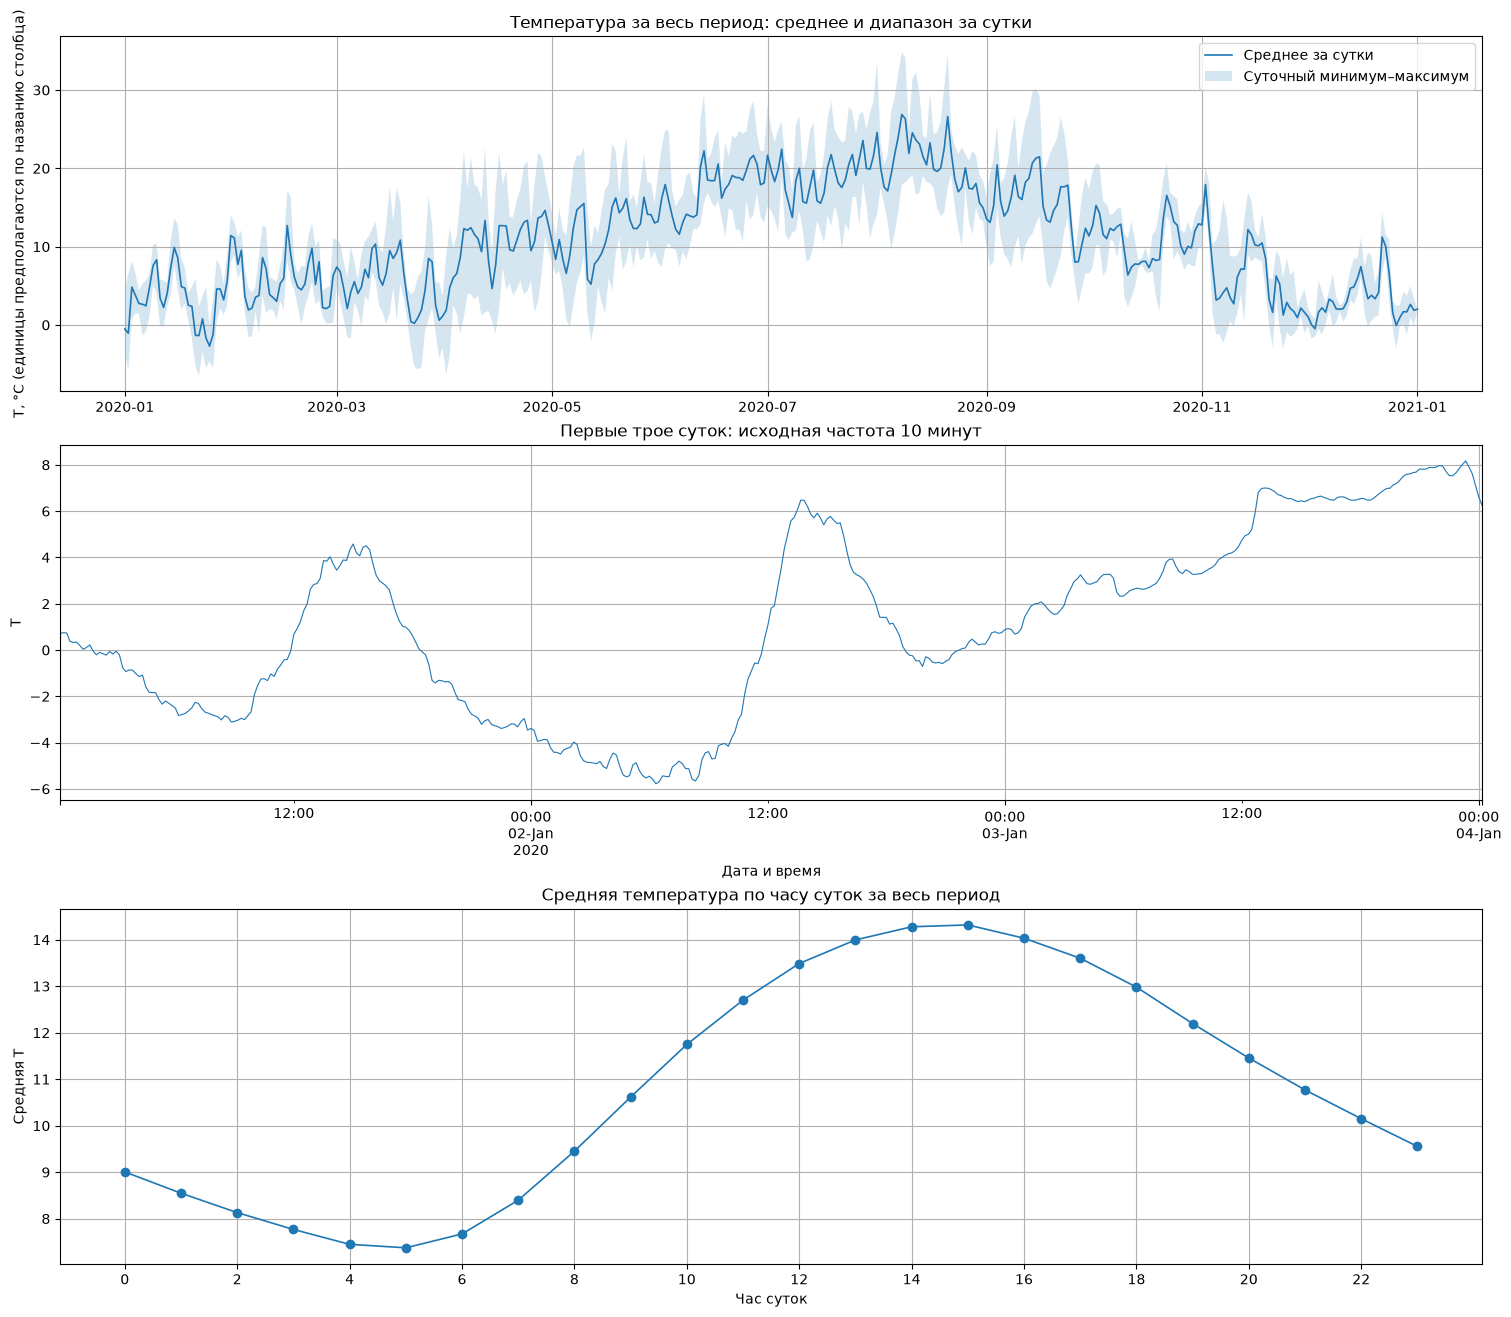

Статистика температуры по месяцам:


,mean,min,max,std
янв,3.46,-6.44,14.02,4.06
фев,5.76,-1.59,17.16,3.52
мар,5.39,-5.66,17.57,4.33
апр,10.39,-6.40,22.79,5.81
май,11.89,-2.06,24.11,4.99
июн,17.36,7.39,29.44,4.34
июл,18.96,8.12,28.62,4.52
авг,20.76,9.60,34.80,5.04
сен,15.41,2.68,30.16,5.63
окт,10.87,1.74,20.65,3.47


In [40]:
daily_mean = y.resample("D").mean()
daily_min = y.resample("D").min()
daily_max = y.resample("D").max()

fig, axes = plt.subplots(3, 1, figsize=(15, 13), constrained_layout=True)
axes[0].plot(daily_mean.index, daily_mean.values, linewidth=1.2, label="Среднее за сутки")
axes[0].fill_between(daily_mean.index, daily_min.values, daily_max.values, alpha=0.18, label="Суточный минимум–максимум")
axes[0].set_title("Температура за весь период: среднее и диапазон за сутки")
axes[0].set_ylabel("T, °C (единицы предполагаются по названию столбца)")
axes[0].legend()

slice_start = y.index[0]
slice_end = slice_start + pd.Timedelta(days=3)
y.loc[slice_start:slice_end].plot(ax=axes[1], linewidth=0.8)
axes[1].set_title("Первые трое суток: исходная частота 10 минут")
axes[1].set_xlabel("Дата и время")
axes[1].set_ylabel("T")

hour_profile = y.groupby(y.index.hour).mean()
axes[2].plot(hour_profile.index, hour_profile.values, marker="o", linewidth=1.2)
axes[2].set_title("Средняя температура по часу суток за весь период")
axes[2].set_xlabel("Час суток")
axes[2].set_ylabel("Средняя T")
axes[2].set_xticks(range(0, 24, 2))
plt.show()

month_labels_ru = {1:"янв",2:"фев",3:"мар",4:"апр",5:"май",6:"июн",7:"июл",8:"авг",9:"сен",10:"окт",11:"ноя",12:"дек"}
monthly_stats = y.groupby(y.index.month).agg(mean="mean", min="min", max="max", std="std")
monthly_stats.index = [month_labels_ru[int(m)] for m in monthly_stats.index]
print("Статистика температуры по месяцам:")
display(monthly_stats.round(2))



У ряда ожидаемо есть годовая изменчивость: температура в тёплые месяцы в среднем выше, чем зимой. На графике нескольких суток можно увидеть быстрые колебания, соответствующие суточному циклу и погодным изменениям. Это качественное наблюдение по графику; далее суточный цикл будет представлен календарными признаками и лагом 144 шага.

## Признаки

Прогнозируем значение температуры в момент t по календарю момента t и наблюдениям, доступным до него.  
Используем:
- календарные признаки: час, день недели, месяц, год, выходной и циклические кодировки времени суток/недели/года;
- лаги температуры, включая предыдущий шаг, сутки и неделю назад;
- среднее, медиану, стандартное отклонение, минимум и максимум на прошлых окнах.

In [ ]:
LAGS = [1, 6, 18, 36, 144, 288, 1008]  # 10 минут, 1 час, 3 часа, 6 часов, 1/2 суток, сутки, неделя
ROLLING_WINDOWS = [6, 144]  # последний час и последние сутки


def make_features(target: pd.Series) -> pd.DataFrame:
    idx = target.index
    X = pd.DataFrame(index=idx)

    X["hour"] = idx.hour
    X["day_of_week"] = idx.dayofweek
    X["month"] = idx.month
    X["year"] = idx.year
    X["is_weekend"] = (idx.dayofweek >= 5).astype(int)

    minute_of_day = idx.hour * 60 + idx.minute
    X["tod_sin"] = np.sin(2 * np.pi * minute_of_day / 1440)
    X["tod_cos"] = np.cos(2 * np.pi * minute_of_day / 1440)
    X["dow_sin"] = np.sin(2 * np.pi * idx.dayofweek / 7)
    X["dow_cos"] = np.cos(2 * np.pi * idx.dayofweek / 7)
    X["month_sin"] = np.sin(2 * np.pi * (idx.month - 1) / 12)
    X["month_cos"] = np.cos(2 * np.pi * (idx.month - 1) / 12)
    X["doy_sin"] = np.sin(2 * np.pi * (idx.dayofyear - 1) / 366)
    X["doy_cos"] = np.cos(2 * np.pi * (idx.dayofyear - 1) / 366)

    for lag in LAGS:
        X[f"lag_{lag}"] = target.shift(lag)

    past_only = target.shift(1)
    for window in ROLLING_WINDOWS:
        rolling = past_only.rolling(window=window, min_periods=window)
        X[f"roll_mean_{window}"] = rolling.mean()
        X[f"roll_median_{window}"] = rolling.median()
        X[f"roll_std_{window}"] = rolling.std()
        X[f"roll_min_{window}"] = rolling.min()
        X[f"roll_max_{window}"] = rolling.max()
    X["roll_mean_1008"] = past_only.rolling(window=1008, min_periods=1008).mean()
    return X

X_features = make_features(y)
supervised = X_features.join(y.rename("target")).loc[observed_target_mask].dropna()
X_all = supervised.drop(columns="target")
y_all = supervised["target"]

print(f"Число сформированных признаков: {X_all.shape[1]}")
print(f"Строк доступно после формирования лагов/окон и исключения синтетических target-точек: {len(X_all):,}")
print(f"Первый допустимый момент: {X_all.index[0]}; последний: {X_all.index[-1]}")
print("\nГруппы признаков:")
calendar_cols = [c for c in X_all.columns if c in ["hour", "day_of_week", "month", "year", "is_weekend", "tod_sin", "tod_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "doy_sin", "doy_cos"]]
lag_cols = [c for c in X_all.columns if c.startswith("lag_")]
rolling_cols = [c for c in X_all.columns if c.startswith("roll_")]
print(f"Календарные: {len(calendar_cols)} — {calendar_cols}")
print(f"Лаги: {len(lag_cols)} — {lag_cols}")
print(f"Скользящие статистики: {len(rolling_cols)} — {rolling_cols}")
print("\nПример матрицы признаков с целевой переменной:")
display(X_all.join(y_all.rename("target")).iloc[100:105].round(3))

assert X_all.index.is_monotonic_increasing
assert "target" not in X_all.columns
assert X_all[[c for c in X_all.columns if c.startswith("lag_")]].notna().all().all()

Число сформированных признаков: 31
Строк доступно после формирования лагов/окон и исключения синтетических target-точек: 51,687
Первый допустимый момент: 2020-01-08 00:10:00; последний: 2021-01-01 00:00:00

Группы признаков:
Календарные: 13 — ['hour', 'day_of_week', 'month', 'year', 'is_weekend', 'tod_sin', 'tod_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos']
Лаги: 7 — ['lag_1', 'lag_6', 'lag_18', 'lag_36', 'lag_144', 'lag_288', 'lag_1008']
Скользящие статистики: 11 — ['roll_mean_6', 'roll_median_6', 'roll_std_6', 'roll_min_6', 'roll_max_6', 'roll_mean_144', 'roll_median_144', 'roll_std_144', 'roll_min_144', 'roll_max_144', 'roll_mean_1008']

Пример матрицы признаков с целевой переменной:


,hour,day_of_week,month,year,is_weekend,tod_sin,tod_cos,dow_sin,dow_cos,month_sin,...,roll_std_6,roll_min_6,roll_max_6,roll_mean_144,roll_median_144,roll_std_144,roll_min_144,roll_max_144,roll_mean_1008,target
date,,,,,,,,,,,,,,,,,,,,,
2020-01-08 16:50:00,16,2,1,2020,0,-0.954,-0.301,0.975,-0.223,0.0,...,0.115,6.05,6.34,4.168,4.415,1.347,1.05,6.48,2.576,6.01
2020-01-08 17:00:00,17,2,1,2020,0,-0.966,-0.259,0.975,-0.223,0.0,...,0.079,6.01,6.22,4.176,4.415,1.355,1.05,6.48,2.579,6.03
2020-01-08 17:10:00,17,2,1,2020,0,-0.976,-0.216,0.975,-0.223,0.0,...,0.075,6.01,6.22,4.185,4.415,1.363,1.05,6.48,2.583,6.01
2020-01-08 17:20:00,17,2,1,2020,0,-0.985,-0.174,0.975,-0.223,0.0,...,0.026,6.01,6.07,4.194,4.415,1.370,1.05,6.48,2.587,6.01
2020-01-08 17:30:00,17,2,1,2020,0,-0.991,-0.131,0.975,-0.223,0.0,...,0.022,6.01,6.06,4.202,4.415,1.378,1.05,6.48,2.592,5.98



Контроль: target отсутствует среди входов; лаги и rolling-статистики рассчитаны со сдвигом назад.


Для модели сформирован 31 признак трёх типов. Календарные признаки описывают час, день недели, месяц, год, выходной день и циклическое положение даты. Они позволяют учитывать закономерности, связанные со временем. Лаги содержат предыдущие значения температуры. Скользящие статистики описывают уровень и изменчивость недавней температуры. Для часового и суточного окон вычисляются среднее, медиана, стандартное отклонение, минимум и максимум. Дополнительно считается среднее за неделю. Cкользящие статистики рассчитываются после сдвига ряда на один шаг. Поэтому в признаки для момента t не входит сама целевая температура y_t.
Модель получает календарную информацию, краткосрочную историю и статистику предыдущих наблюдений.

## Разделение и кросс-валидация

#### Разделение train/test

Разделим пригодные строки хронологически: первые 80% - train, последние 20% - test. Случайного перемешивания не будет. Внутри train используем TimeSeriesSplit с расширяющимся обучающим окном: каждый validation-блок расположен позже своего train-блока. Кросс-валидация здесь оценивает одношаговый прогноз с доступом к новым фактическим измерениям внутри проверочного блока. 

Train: 41,349 строк, 2020-01-08 00:10:00 — 2020-10-21 05:00:00
Test:  10,338 строк, 2020-10-21 05:10:00 — 2021-01-01 00:00:00


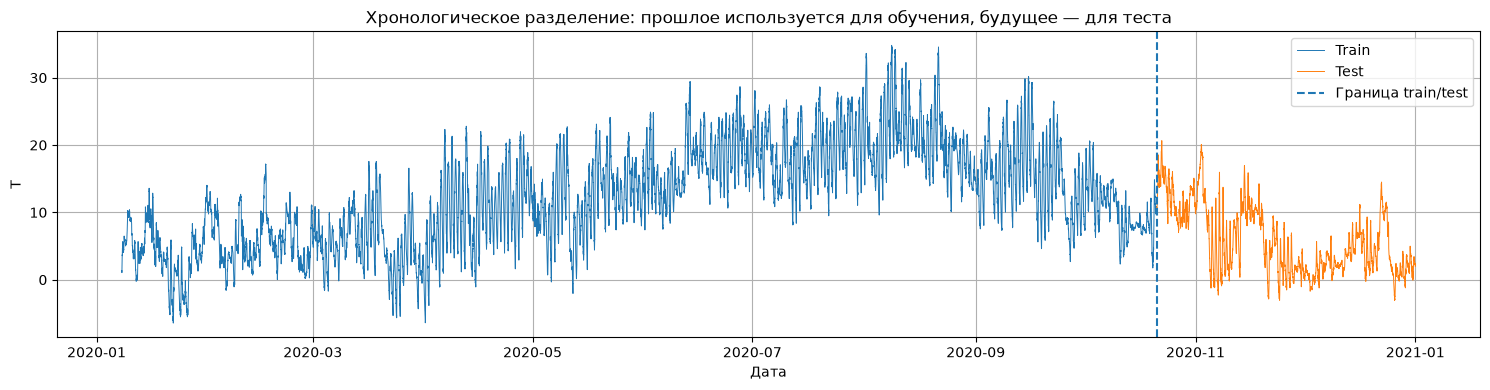

In [41]:
split_pos = int(len(X_all) * 0.80)
X_train, X_test = X_all.iloc[:split_pos].copy(), X_all.iloc[split_pos:].copy()
y_train, y_test = y_all.iloc[:split_pos].copy(), y_all.iloc[split_pos:].copy()

print(f"Train: {len(X_train):,} строк, {X_train.index[0]} — {X_train.index[-1]}")
print(f"Test:  {len(X_test):,} строк, {X_test.index[0]} — {X_test.index[-1]}")
assert X_train.index.max() < X_test.index.min()

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(y_train.index, y_train, label="Train", linewidth=0.7)
ax.plot(y_test.index, y_test, label="Test", linewidth=0.7)
ax.axvline(X_test.index[0], linestyle="--", linewidth=1.5, label="Граница train/test")
ax.set_title("Хронологическое разделение: прошлое используется для обучения, будущее — для теста")
ax.set_xlabel("Дата")
ax.set_ylabel("T")
ax.legend()
plt.tight_layout()
plt.show()

#### Расширяющаяся временная кросс-валидация

В каждом фолде обучим отдельную модель и вычислим MAE, MSE и MAPE. 

In [ ]:
def regression_metrics(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    abs_error = np.abs(yt - yp)
    eligible_mape = np.abs(yt) >= 1.0
    mape = (np.mean(abs_error[eligible_mape] / np.abs(yt[eligible_mape])) * 100
            if eligible_mape.any() else np.nan)
    wape = np.sum(abs_error) / max(np.sum(np.abs(yt)), 1e-12) * 100
    return {
        "MSE": mean_squared_error(yt, yp),
        "MAE": mean_absolute_error(yt, yp),
        "MAPE, |T|>=1°C (%)": mape,
        "WAPE (%)": wape,
    }


def new_model():
    return HistGradientBoostingRegressor(
        learning_rate=0.08,
        max_iter=120,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=SEED,
    )


tscv = TimeSeriesSplit(n_splits=3)
cv_rows = []
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    fold_model = new_model()
    fold_model.fit(X_tr, y_tr)
    pred_val = fold_model.predict(X_val)
    metrics = regression_metrics(y_val, pred_val)
    cv_rows.append({
        "Фолд": fold,
        "Начало train": X_tr.index[0],
        "Конец train": X_tr.index[-1],
        "Начало validation": X_val.index[0],
        "Конец validation": X_val.index[-1],
        "n_train": len(X_tr),
        "n_validation": len(X_val),
        "MAE": metrics["MAE"],
        "MSE": metrics["MSE"],
        "WAPE (%)": metrics["WAPE (%)"],
    })
cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
cv_mean_mae = float(cv_results["MAE"].mean())
cv_std_mae = float(cv_results["MAE"].std(ddof=0))
cv_best_fold = int(cv_results.loc[cv_results["MAE"].idxmin(), "Фолд"])
cv_worst_fold = int(cv_results.loc[cv_results["MAE"].idxmax(), "Фолд"])
print(f"Средняя MAE по фолдам: {cv_mean_mae:.4f} °C; стандартное отклонение между фолдами: {cv_std_mae:.4f} °C.")

C:\Users\Admin\AppData\Local\Temp\ipykernel_29604\2760533216.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cv_results.round(4))


,Фолд,Начало train,Конец train,Начало validation,Конец validation,n_train,n_validation,MAE,MSE,WAPE (%)
0,1,2020-01-08 00:10:00,2020-03-19 19:00:00,2020-03-19 19:10:00,2020-05-30 15:20:00,10338,10337,0.5054,1.2903,5.0451
1,2,2020-01-08 00:10:00,2020-05-30 15:20:00,2020-05-30 15:30:00,2020-08-10 10:10:00,20675,10337,0.7865,3.2763,4.2357
2,3,2020-01-08 00:10:00,2020-08-10 10:10:00,2020-08-10 10:20:00,2020-10-21 05:00:00,31012,10337,0.1729,0.0701,1.1251


Средняя MAE по фолдам: 0.4883 °C; стандартное отклонение между фолдами: 0.2508 °C.
Лучшая MAE — фолд 3; худшая — фолд 2.


Модель обучается на раннем периоде, а окончательная проверка проводится на более позднем. Качество существенно меняется между проверочными временными блоками. Лучший результат получен в третьем фолде, худший - во втором. Это означает, что точность модели зависит от того, на какой временной участок приходится прогнозирование. Вероятная причина - различия погодных режимов и степени изменчивости температуры. Валидационные блоки оценивают одношаговый прогноз, при котором на следующих шагах доступны новые фактические измерения. Поэтому для проверки прогноза на непрерывный горизонт в 24 часа в работе дополнительно используется рекурсивная стратегия. Случайное перемешивание заменено корректной временной кросс-валидацией. Результаты показывают, что одного среднего показателя качества недостаточно: необходимо учитывать временной период, на котором проверяется модель.

## Модель

Используем HistGradientBoostingRegressor - градиентный бустинг над деревьями решений. Он подходит для нелинейной зависимости температуры от календаря, лагов и статистик прошлых значений. Сначала оценим одношаговый прогноз на train и test. Затем выполним рекурсивный прогноз на 144 шага: после каждого шага предсказанное значение добавляется в историю и используется для формирования следующих лагов и скользящих статистик.

In [22]:
model = new_model()
model.fit(X_train, y_train)
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_metrics = regression_metrics(y_train, train_pred)
test_metrics = regression_metrics(y_test, test_pred)
main_metrics = pd.DataFrame({
    "Train (in-sample)": train_metrics,
    "Test (one-step, rolling)": test_metrics,
}).T
print("Одношаговый прогноз: train и test")
display(main_metrics.round(4))

mape_coverage = float((np.abs(y_test.to_numpy()) >= 1.0).mean() * 100)
print(f"MAPE рассчитана только для test-точек с |T| >= 1 °C: {mape_coverage:.1f}% тестовых наблюдений попали в этот расчёт.")

# Таблица ошибок понадобится для дальнейшего разбора.
test_results = pd.DataFrame({"actual": y_test, "prediction": test_pred}, index=y_test.index)
test_results["error"] = test_results["actual"] - test_results["prediction"]
test_results["abs_error"] = test_results["error"].abs()
test_results["hour"] = test_results.index.hour
test_results["month"] = test_results.index.month

Одношаговый прогноз: train и test


,MSE,MAE,"MAPE, |T|>=1°C (%)",WAPE (%)
Train (in-sample),0.0479,0.1491,1.7947,1.2003
"Test (one-step, rolling)",0.0310,0.1235,3.1434,2.0618


MAPE рассчитана только для test-точек с |T| >= 1 °C: 87.2% тестовых наблюдений попали в этот расчёт.


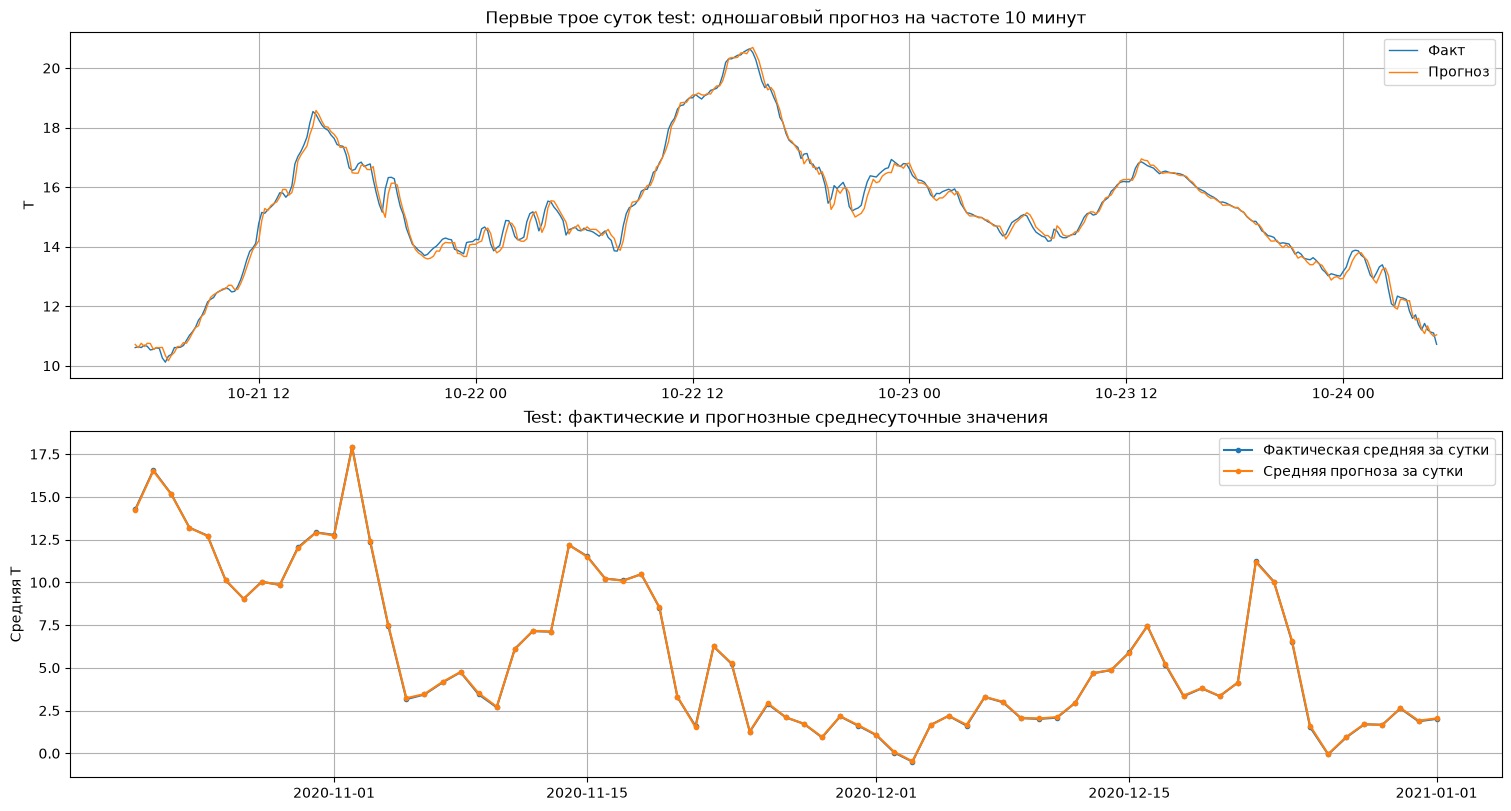

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), constrained_layout=True)
zoom_end = test_results.index[0] + pd.Timedelta(days=3)
zoom = test_results.loc[:zoom_end]
axes[0].plot(zoom.index, zoom["actual"], label="Факт", linewidth=1.0)
axes[0].plot(zoom.index, zoom["prediction"], label="Прогноз", linewidth=1.0)
axes[0].set_title("Первые трое суток test: одношаговый прогноз на частоте 10 минут")
axes[0].set_ylabel("T")
axes[0].legend()

actual_daily_test = test_results["actual"].resample("D").mean()
pred_daily_test = test_results["prediction"].resample("D").mean()
axes[1].plot(actual_daily_test.index, actual_daily_test.values, marker=".", label="Фактическая средняя за сутки")
axes[1].plot(pred_daily_test.index, pred_daily_test.values, marker=".", label="Средняя прогноза за сутки")
axes[1].set_title("Test: фактические и прогнозные среднесуточные значения")
axes[1].set_ylabel("Средняя T")
axes[1].legend()
plt.show()

#### Рекурсивный прогноз на 24 часа

In [ ]:
def calendar_features_for_timestamp(ts: pd.Timestamp) -> dict:
    minute_of_day = ts.hour * 60 + ts.minute
    dow = ts.dayofweek
    month = ts.month - 1
    doy = ts.dayofyear - 1
    return {
        "hour": ts.hour,
        "day_of_week": ts.dayofweek,
        "month": ts.month,
        "year": ts.year,
        "is_weekend": int(dow >= 5),
        "tod_sin": np.sin(2 * np.pi * minute_of_day / 1440),
        "tod_cos": np.cos(2 * np.pi * minute_of_day / 1440),
        "dow_sin": np.sin(2 * np.pi * dow / 7),
        "dow_cos": np.cos(2 * np.pi * dow / 7),
        "month_sin": np.sin(2 * np.pi * month / 12),
        "month_cos": np.cos(2 * np.pi * month / 12),
        "doy_sin": np.sin(2 * np.pi * doy / 366),
        "doy_cos": np.cos(2 * np.pi * doy / 366),
    }


def make_one_recursive_row(ts: pd.Timestamp, history_values, feature_columns) -> pd.DataFrame:
    values = np.asarray(history_values, dtype=float)
    row = calendar_features_for_timestamp(ts)
    for lag in LAGS:
        row[f"lag_{lag}"] = values[-lag]
    for window in ROLLING_WINDOWS:
        past = values[-window:]
        row[f"roll_mean_{window}"] = float(np.mean(past))
        row[f"roll_median_{window}"] = float(np.median(past))
        row[f"roll_std_{window}"] = float(np.std(past, ddof=1))
        row[f"roll_min_{window}"] = float(np.min(past))
        row[f"roll_max_{window}"] = float(np.max(past))
    row["roll_mean_1008"] = float(np.mean(values[-1008:]))
    return pd.DataFrame([[row[c] for c in feature_columns],], columns=feature_columns, index=[ts])

train_end = X_train.index[-1]
forecast_index = pd.date_range(train_end + pd.Timedelta(FREQ), periods=H, freq=FREQ)
history_values = y.loc[:train_end].to_numpy(dtype=float).tolist()
recursive_predictions = []
for ts in forecast_index:
    X_next = make_one_recursive_row(ts, history_values, X_train.columns)
    next_pred = float(model.predict(X_next)[0])
    recursive_predictions.append(next_pred)
    history_values.append(next_pred)

recursive_forecast = pd.Series(recursive_predictions, index=forecast_index, name="recursive_prediction")
recursive_actual = y_observed.reindex(forecast_index).rename("actual")
recursive_eval_mask = recursive_actual.notna()
recursive_metrics = regression_metrics(recursive_actual[recursive_eval_mask], recursive_forecast[recursive_eval_mask])
print(f"Последняя точка train: {train_end}")
print(f"Рекурсивный прогноз: {forecast_index[0]} — {forecast_index[-1]} ({len(recursive_forecast)} шагов)")
print(f"Фактических наблюдений для проверки горизонта: {int(recursive_eval_mask.sum())} из {H}")
display(pd.DataFrame([recursive_metrics], index=["Recursive forecast, first 24h"]).round(4))

Последняя точка train: 2020-10-21 05:00:00
Рекурсивный прогноз: 2020-10-21 05:10:00 — 2020-10-22 05:00:00 (144 шагов)
Фактических наблюдений для проверки горизонта: 144 из 144


,MSE,MAE,"MAPE, |T|>=1°C (%)",WAPE (%)
"Recursive forecast, first 24h",17.6156,3.6419,24.1831,25.385


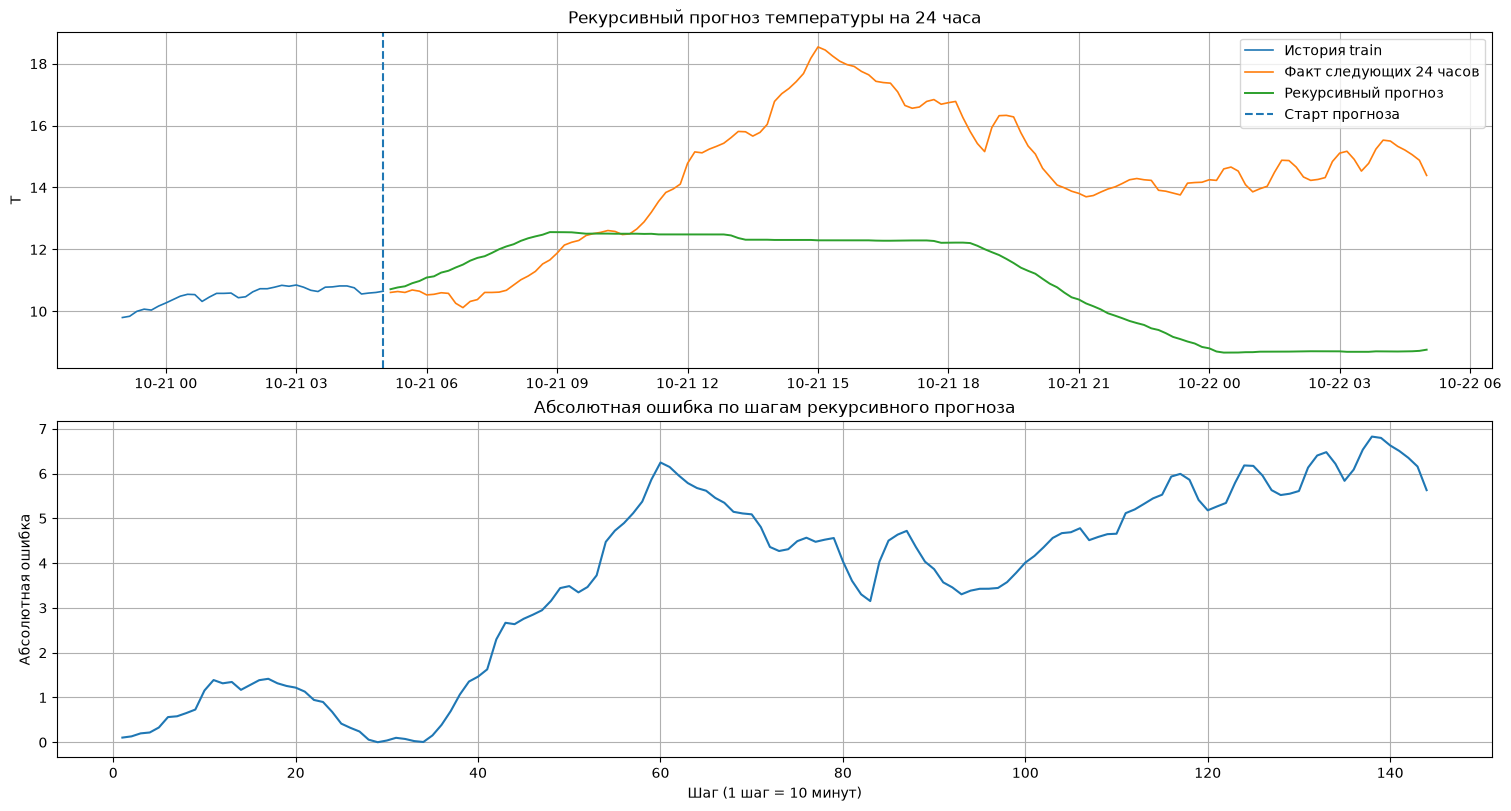

MAE одношагового rolling-прогноза на всём test: 0.1235 °C.
MAE рекурсивного прогноза на первом горизонте 24 часа: 3.6419 °C.


In [44]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), constrained_layout=True)
history_zoom = y.loc[train_end - pd.Timedelta(hours=6):train_end]
axes[0].plot(history_zoom.index, history_zoom.values, label="История train", linewidth=1.2)
axes[0].plot(recursive_actual.index, recursive_actual.values, label="Факт следующих 24 часов", linewidth=1.2)
axes[0].plot(recursive_forecast.index, recursive_forecast.values, label="Рекурсивный прогноз", linewidth=1.4)
axes[0].axvline(train_end, linestyle="--", label="Старт прогноза")
axes[0].set_title("Рекурсивный прогноз температуры на 24 часа")
axes[0].set_ylabel("T")
axes[0].legend()

recursive_abs_error = (recursive_actual - recursive_forecast).abs()
axes[1].plot(np.arange(1, H + 1), recursive_abs_error.values)
axes[1].set_title("Абсолютная ошибка по шагам рекурсивного прогноза")
axes[1].set_xlabel("Шаг (1 шаг = 10 минут)")
axes[1].set_ylabel("Абсолютная ошибка")
plt.show()

print(f"MAE одношагового rolling-прогноза на всём test: {test_metrics['MAE']:.4f} °C.")
print(f"MAE рекурсивного прогноза на первом горизонте 24 часа: {recursive_metrics['MAE']:.4f} °C.")

## Оценка качества

Метрики ошибок по месяцу:


,n,MAE,mean_actual,max_abs_error
янв,1,0.033,2.010,0.033
окт,1553,0.131,12.314,1.904
ноя,4320,0.135,6.151,2.515
дек,4464,0.110,3.296,1.933


Часы суток с наибольшей MAE:


,n,MAE
hour,,
12,432,0.151
9,432,0.147
6,432,0.143
7,432,0.141
15,432,0.141
8,432,0.139
14,432,0.138
10,432,0.134


Ошибки по квантильным группам фактической температуры:


,n,MAE,mean_actual,max_abs_error
temperature_group,,,,
"(-3.061, 1.38]",2070,0.149,0.091,0.879
"(1.38, 3.13]",2074,0.101,2.176,0.883
"(3.13, 6.71]",2064,0.110,4.623,1.933
"(6.71, 10.57]",2067,0.130,8.861,1.904
"(10.57, 20.65]",2063,0.127,13.501,2.515


Порог верхних 10% резких изменений: |ΔT за 10 мин| ≥ 0.284 °C.
MAE на точках резкого изменения: 0.3448 °C; на остальных: 0.0989 °C.


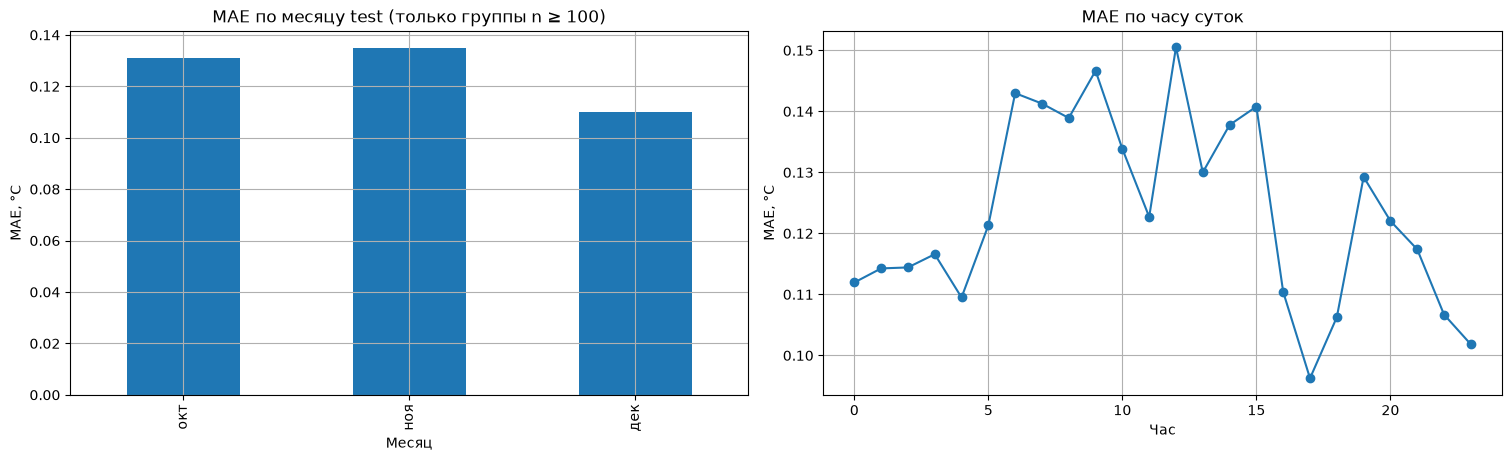

10 наибольших абсолютных ошибок:


,actual,prediction,error,abs_error
date,,,,
2020-11-03 00:50:00,14.70,17.215,-2.515,2.515
2020-12-24 14:00:00,6.17,8.103,-1.933,1.933
2020-10-29 12:20:00,8.59,10.494,-1.904,1.904
2020-11-15 20:10:00,11.58,10.228,1.352,1.352
2020-11-10 15:10:00,7.22,8.532,-1.312,1.312
2020-11-07 16:00:00,14.06,15.371,-1.311,1.311
2020-12-24 14:10:00,5.00,6.241,-1.241,1.241
2020-10-29 09:00:00,8.03,9.264,-1.234,1.234
2020-10-28 19:50:00,9.49,8.343,1.147,1.147


In [45]:
mae_by_month = test_results.groupby("month").agg(
    n=("abs_error", "size"),
    MAE=("abs_error", "mean"),
    mean_actual=("actual", "mean"),
    max_abs_error=("abs_error", "max"),
).sort_index()
mae_by_month.index = [month_labels_ru[int(m)] for m in mae_by_month.index]
print("Метрики ошибок по месяцу:")
display(mae_by_month.round(3))
months_with_enough_points = mae_by_month.loc[mae_by_month["n"] >= 100]

mae_by_hour = test_results.groupby("hour").agg(n=("abs_error", "size"), MAE=("abs_error", "mean")).sort_values("MAE", ascending=False)
print("Часы суток с наибольшей MAE:")
display(mae_by_hour.head(8).round(3))

test_results["temperature_group"] = pd.qcut(test_results["actual"], q=5, duplicates="drop")
mae_by_temp = test_results.groupby("temperature_group", observed=False).agg(
    n=("abs_error", "size"), MAE=("abs_error", "mean"),
    mean_actual=("actual", "mean"), max_abs_error=("abs_error", "max")
)
print("Ошибки по квантильным группам фактической температуры:")
display(mae_by_temp.round(3))

actual_series_for_change = y.reindex(test_results.index)
test_results["abs_change_10min"] = actual_series_for_change.diff().abs()
change_threshold = float(test_results["abs_change_10min"].quantile(0.90))
fast_change_mask = test_results["abs_change_10min"] >= change_threshold
mae_fast_change = float(test_results.loc[fast_change_mask, "abs_error"].mean())
mae_other_change = float(test_results.loc[~fast_change_mask, "abs_error"].mean())
print(f"Порог верхних 10% резких изменений: |ΔT за 10 мин| ≥ {change_threshold:.3f} °C.")
print(f"MAE на точках резкого изменения: {mae_fast_change:.4f} °C; на остальных: {mae_other_change:.4f} °C.")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
months_with_enough_points["MAE"].plot(kind="bar", ax=axes[0])
axes[0].set_title("MAE по месяцу test (только группы n ≥ 100)")
axes[0].set_xlabel("Месяц")
axes[0].set_ylabel("MAE, °C")
mae_by_hour.sort_index()["MAE"].plot(ax=axes[1], marker="o")
axes[1].set_title("MAE по часу суток")
axes[1].set_xlabel("Час")
axes[1].set_ylabel("MAE, °C")
plt.show()

worst_rows = test_results.nlargest(10, "abs_error")[["actual", "prediction", "error", "abs_error"]]
print("10 наибольших абсолютных ошибок:")
display(worst_rows.round(3))

worst_month_label = str(months_with_enough_points["MAE"].idxmax())
best_month_label = str(months_with_enough_points["MAE"].idxmin())
worst_hour = int(mae_by_hour.index[0])
worst_temp_group = mae_by_temp["MAE"].idxmax()
worst_error_time = test_results["abs_error"].idxmax()
worst_error_row = test_results.loc[worst_error_time]

MAE на тесте составляет около 0,125 градуса температурной шкалы. MSE равна 0,0315. Это хорошие показатели в рамках именно одношагового эксперимента. MAE на test ниже, чем на train  тестовый период мог оказаться более предсказуемым, а rolling-прогноз на каждом шаге использует фактическую предыдущую температуру. Поэтому такой результат сам по себе не доказывает отсутствия переобучения.  MAPE интерпретируется осторожно. Поскольку температура в градусах Цельсия может быть отрицательной или близкой к нулю, стандартная процентная ошибка становится нестабильной. В таблице MAPE считается только на точках, где модуль фактической температуры не меньше 1 градуса. В расчёт попало 87,2% тестовых наблюдений. Основными показателями для интерпретации остаются MAE и MSE.  
- Наибольшая MAE среди месяцев теста с достаточным количеством наблюдений приходится на ноябрь, наименьшая — на декабрь.
- Среди часов суток наибольшая MAE наблюдается около 12:00.
- В верхних 10% наиболее резких изменений температуры за 10 минут MAE составляет 0,341 градуса, тогда как на остальных шагах — 0,101 градуса.
- Самая большая ошибка наблюдалась 3 ноября 2020 года в 00:50: фактическая температура составила 14,70, а прогноз — 17,26. Абсолютная ошибка равна 2,56 градуса.
Модель заметно хуже справляется с быстрыми изменениями температуры, чем с относительно стабильными участками. Это ожидаемо, поскольку в ней нет будущих погодных условий, которые могли бы объяснить резкую смену температуры.  
Рекурсивный прогноз на первые 24 часа оказался сложнее. MAE около 3,72 градуса намного выше одношаговой MAE. При рекурсивной стратегии модель использует собственные предсказания, из-за чего неточность предыдущего шага может повлиять на последующие. Это показывает, почему результаты одношагового прогнозирования нельзя выдавать за результаты прогноза на сутки.

## Декомпозиция

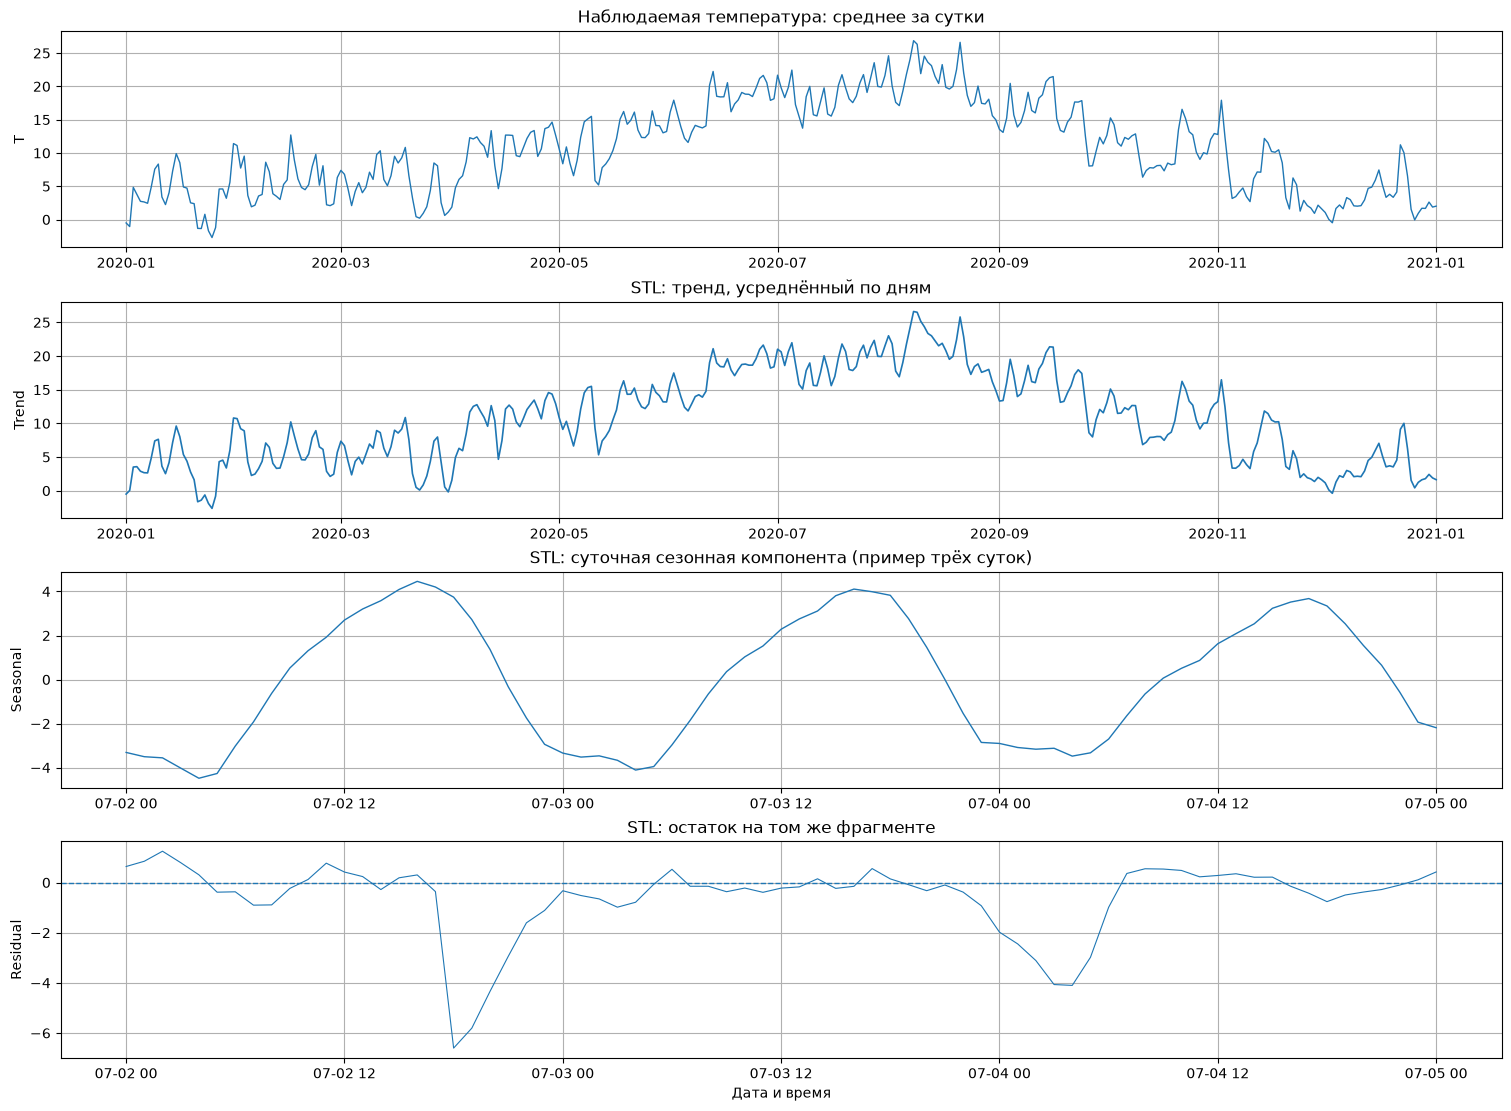

,Компонента,Стандартное отклонение,Минимум,Максимум
0,Тренд,6.730,-3.140,26.874
1,Сезонность,2.935,-8.578,8.089
2,Остаток,1.377,-11.224,7.958


In [46]:
stl_series = y.resample("1h").mean().dropna()
stl_full = STL(stl_series, period=24, robust=True).fit(inner_iter=2, outer_iter=3)
stl_trend = pd.Series(stl_full.trend, index=stl_series.index, name="trend")
stl_seasonal = pd.Series(stl_full.seasonal, index=stl_series.index, name="seasonal")
stl_resid = pd.Series(stl_full.resid, index=stl_series.index, name="residual")

fig, axes = plt.subplots(4, 1, figsize=(15, 11), constrained_layout=True)
daily_series = y.resample("D").mean()
axes[0].plot(daily_series.index, daily_series.values, linewidth=1.0)
axes[0].set_title("Наблюдаемая температура: среднее за сутки")
axes[0].set_ylabel("T")

trend_daily = stl_trend.resample("D").mean()
axes[1].plot(trend_daily.index, trend_daily.values, linewidth=1.2)
axes[1].set_title("STL: тренд, усреднённый по дням")
axes[1].set_ylabel("Trend")

plot_start = stl_series.index[len(stl_series) // 2].floor("D")
plot_end = plot_start + pd.Timedelta(days=3)
axes[2].plot(stl_seasonal.loc[plot_start:plot_end].index, stl_seasonal.loc[plot_start:plot_end].values, linewidth=1.0)
axes[2].set_title("STL: суточная сезонная компонента (пример трёх суток)")
axes[2].set_ylabel("Seasonal")

axes[3].plot(stl_resid.loc[plot_start:plot_end].index, stl_resid.loc[plot_start:plot_end].values, linewidth=0.8)
axes[3].axhline(0, linestyle="--", linewidth=1)
axes[3].set_title("STL: остаток на том же фрагменте")
axes[3].set_ylabel("Residual")
axes[3].set_xlabel("Дата и время")
plt.show()

stl_summary = pd.DataFrame({
    "Компонента": ["Тренд", "Сезонность", "Остаток"],
    "Стандартное отклонение": [stl_trend.std(), stl_seasonal.std(), stl_resid.std()],
    "Минимум": [stl_trend.min(), stl_seasonal.min(), stl_resid.min()],
    "Максимум": [stl_trend.max(), stl_seasonal.max(), stl_resid.max()],
})
display(stl_summary.round(3))

seasonal_by_hour = stl_seasonal.groupby(stl_seasonal.index.hour).mean()
trend_first = float(stl_trend.iloc[:24*14].mean())
trend_last = float(stl_trend.iloc[-24*14:].mean())

- Средний уровень тренда в первые две недели часового ряда: 3.72 °C; в последние две недели: 3.68 °C.
- В среднем наиболее положительная сезонная поправка приходится на 15:00 (+3.631 °C), наиболее отрицательная - на 05:00 (-3.549 °C).
- Стандартное отклонение остатка: 1.377 °C. Остаток отражает колебания, которые не описаны гладким трендом и суточным сезонным профилем.
- STL помогает раздельно рассмотреть медленное изменение уровня, повторяющийся суточный профиль и нерегулярные колебания. Остаток нельзя автоматически считать ошибкой датчика.

#### Проверка: улучшает ли прогноз признак из STL?

In [ ]:
train_end = X_train.index[-1]
stl_train_series = y.loc[:train_end].resample("1h").mean().dropna()
stl_train = STL(stl_train_series, period=24, robust=True).fit(inner_iter=2, outer_iter=3)
train_seasonal = pd.Series(stl_train.seasonal, index=stl_train_series.index)
stl_profile = train_seasonal.groupby(train_seasonal.index.hour).mean().reindex(range(24))

def add_stl_profile(X: pd.DataFrame) -> pd.DataFrame:
    result = X.copy()
    result["stl_daily_seasonal_profile"] = [float(stl_profile.loc[int(h)]) for h in result.index.hour]
    return result

X_train_stl = add_stl_profile(X_train)
X_test_stl = add_stl_profile(X_test)
model_stl = new_model()
model_stl.fit(X_train_stl, y_train)
test_pred_stl = model_stl.predict(X_test_stl)
stl_metrics = regression_metrics(y_test, test_pred_stl)

stl_comparison = pd.DataFrame({
    "Базовые признаки": test_metrics,
    "Базовые + train-only STL": stl_metrics,
}).T
print("Сравнение на одном test-интервале:")
display(stl_comparison.round(4))
mae_change_pct = (stl_metrics["MAE"] - test_metrics["MAE"]) / test_metrics["MAE"] * 100

Сравнение на одном test-интервале:


,MSE,MAE,"MAPE, |T|>=1°C (%)",WAPE (%)
Базовые признаки,0.0310,0.1235,3.1434,2.0618
Базовые + train-only STL,0.0306,0.1223,3.1172,2.0414


Для STL-декомпозиции ряд агрегирован до часовых средних, после чего применён период 24 - это суточная сезонность в часовом ряду.  
STL выделяет три компоненты:
- Тренд — плавное изменение общего уровня температуры.
- Сезонность — повторяющийся суточный профиль.
- Остаток — колебания, которые не описываются трендом и сезонной компонентой.  
  
В расчёте стандартное отклонение тренда составляет 6,730, сезонной компоненты -2,935, остатка - 1,377 в единицах температурного ряда. Наибольшая средняя положительная сезонная поправка приходится примерно на 15:00, наиболее отрицательная - на 05:00. Это согласуется с обнаруженным ранее суточным профилем.  
  
Полная STL-декомпозиция используется только для описания истории: её компоненты, рассчитанные с привлечением будущих наблюдений, нельзя напрямую передавать модели для прогноза. Поэтому дополнительно проведён отдельный эксперимент, в котором суточный сезонный профиль строится только по обучающей части.  
MAE снизилась примерно на 0,84%. Это небольшое улучшение, но оно показывает, что дополнительный признак суточного профиля в данном эксперименте принёс пользу.

## Вывод

In [53]:
final_metrics = pd.DataFrame({
    "Train (in-sample)": train_metrics,
    "Test (one-step, rolling)": test_metrics,
    "Test (recursive, first 24h)": recursive_metrics,
    "Test (one-step + STL profile)": stl_metrics,
}).T
print("Итоговые метрики:")
display(final_metrics.round(4))

mae_gap_pct = (test_metrics["MAE"] - train_metrics["MAE"]) / max(train_metrics["MAE"], 1e-12) * 100
recursive_vs_rolling_pct = (recursive_metrics["MAE"] - test_metrics["MAE"]) / max(test_metrics["MAE"], 1e-12) * 100


Итоговые метрики:


,MSE,MAE,"MAPE, |T|>=1°C (%)",WAPE (%)
Train (in-sample),0.0479,0.1491,1.7947,1.2003
"Test (one-step, rolling)",0.0310,0.1235,3.1434,2.0618
"Test (recursive, first 24h)",17.6156,3.6419,24.1831,25.3850
Test (one-step + STL profile),0.0306,0.1223,3.1172,2.0414


В ходе работы прогнозирование температуры воздуха было сведено к задаче регрессии. Данные преобразованы в регулярный временной ряд, сформированы календарные признаки, лаги и скользящие статистики. Хронологическое разделение и расширяющаяся временная кросс-валидация позволили оценивать модель на более поздних временных участках без случайного перемешивания.  

Для прогноза использован градиентный бустинг. Одношаговый rolling-прогноз продемонстрировал MAE 0,1249 на тестовом периоде, однако рекурсивный прогноз на 24 часа оказался значительно сложнее: MAE выросла до 3,7152. Это показывает, что модель хорошо использует актуальную историю для предсказания ближайшего следующего значения, но точность снижается, когда фактические измерения в течение горизонта недоступны и модель должна опираться на собственные прогнозы.  

Анализ ошибок показал, что наиболее трудными оказываются быстрые изменения температуры: MAE на таких точках примерно втрое выше, чем на остальных. STL-декомпозиция позволила разделить тренд, суточную сезонность и остаток, а добавление сезонного профиля, построенного только на train, немного улучшило одношаговую точность.  

Основные ограничения исследования - около одного года наблюдений, отсутствие будущих внешних метеорологических факторов и накопление ошибок при рекурсивном прогнозировании. Для дальнейшего улучшения можно сравнить модель с сезонным наивным прогнозом и подключить внешние данные, доступные на момент прогнозирования, например прогноз погоды. При этом нельзя использовать реальные будущие показания метеодатчиков, если они ещё не известны в момент построения прогноза.
